# WorkflowHub edges vs. citation-order edges

Compare ordered tool co-citations with tool pairs in Galaxy workflows

- **Workflows:** `data/biotools/biotools_edges.csv` (`map_galaxy_tools.py`): tool A feeds tool B in `n_workflows` workflows
- **Citations:** `../edges-processed/directed_edges.csv` (`citation-order/` steps 3 to 5): tool A is cited before tool B in `n_articles` articles

Each workflow pair is put in its main workflow direction, `source` → `target`. Then both sources get a direction ratio, from 0 to 1: the share of the counts that go `source` → `target`.

`distance = |wf_dir - cit_dir|` says how well the two agree: 0 = the same ratio, 1 = opposite directions (all workflows one way, all articles the other).

In [3]:
import duckdb

MAX_CONFIDENCE = 3   # workflow edges to use: 1 = Codex mapping only, 2 = + name match, 3 = all (+ prefix match)
MIN_ARTICLES = 1    # pairs with fewer articles are left out of the summary

con = duckdb.connect()
con.execute(f"""
    CREATE OR REPLACE TABLE wf AS
    SELECT lower(source) AS source, lower(target) AS target, n_workflows, confidence
    FROM 'data/biotools/biotools_edges.csv' WHERE confidence <= {MAX_CONFIDENCE}
""")
con.execute("CREATE OR REPLACE TABLE cit AS SELECT source, target, n_articles FROM '../edges-processed/directed_edges 2.csv'")
con.execute("CREATE OR REPLACE TABLE cit_tools AS SELECT source AS tool FROM cit UNION SELECT target FROM cit")

# One row per workflow pair in its main direction, with the counts of both sources both ways.
con.execute(f"""
    CREATE OR REPLACE TABLE pairs AS
    WITH counts AS (
        SELECT f.source, f.target,
               f.n_workflows AS wf_fwd, coalesce(r.n_workflows, 0) AS wf_rev,
               coalesce(cf.n_articles, 0) AS cit_fwd, coalesce(cr.n_articles, 0) AS cit_rev,
               greatest(f.confidence, coalesce(r.confidence, f.confidence)) AS confidence,  -- the weaker of both directions
               f.source IN (SELECT tool FROM cit_tools) AND f.target IN (SELECT tool FROM cit_tools) AS both_in_cit
        FROM wf f
        LEFT JOIN wf r ON r.source = f.target AND r.target = f.source
        LEFT JOIN cit cf ON cf.source = f.source AND cf.target = f.target
        LEFT JOIN cit cr ON cr.source = f.target AND cr.target = f.source
        WHERE f.n_workflows > coalesce(r.n_workflows, 0)                -- the main direction,
           OR (f.n_workflows = r.n_workflows AND f.source < f.target)  -- on a tie the alphabetical one
    ),
    ratios AS (
        SELECT *,
               wf_fwd / (wf_fwd + wf_rev) AS wf_dir,
               cit_fwd / nullif(cit_fwd + cit_rev, 0) AS cit_dir
        FROM counts
    )
    SELECT *, abs(wf_dir - cit_dir) AS distance FROM ratios
""")

# More plots

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:

sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3, "grid.linestyle": "--"})
COLOUR = "#f2634c"

In [6]:
direction_df = con.execute("""
    SELECT wf_dir, cit_dir,
           wf_fwd + wf_rev   AS wf_total,
           cit_fwd + cit_rev AS cit_total,
           confidence
    FROM pairs
    WHERE cit_fwd + cit_rev >= ? ORDER BY confidence DESC
""", [1]).df()

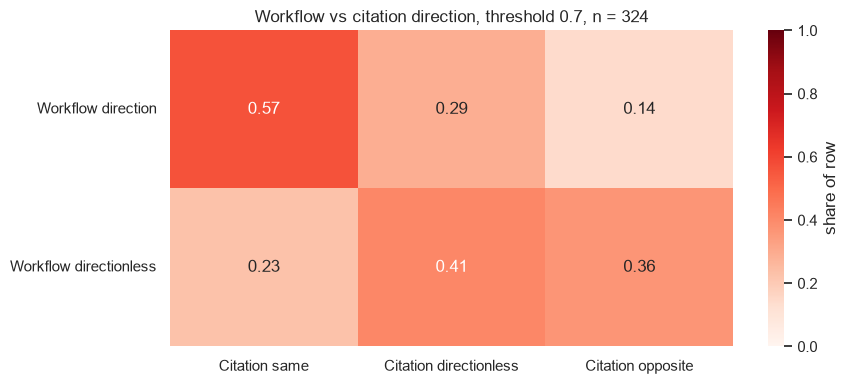

class_cit      same  directionless  opposite
class_wf                                    
direction       171             88        43
directionless     5              9         8
agreement when workflow has a direction: 0.57 (n = 302)
agreement when both have a clear direction: 0.8 (n = 214)


In [7]:
"""
Wf Direction
Wf Directionless
                cit same cit opposite cit directionless

"""
THRESHOLD = 0.70  # direction threshold; 1 - t is the opposite threshold

ROWS = ["direction", "directionless"]
COLS = ["same", "directionless", "opposite"]

# wf_dir is always >= 0.5 (main workflow direction), so only two row classes
direction_df["class_wf"] = np.where(direction_df["wf_dir"] > THRESHOLD, "direction", "directionless")
direction_df["class_cit"] = np.select(
    [direction_df["cit_dir"] > THRESHOLD, direction_df["cit_dir"] < 1 - THRESHOLD],
    ["same", "opposite"],
    default="directionless",
)

counts = (pd.crosstab(direction_df["class_wf"], direction_df["class_cit"])
            .reindex(index=ROWS, columns=COLS, fill_value=0))
norm = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(norm, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "share of row"})
ax.set_xticklabels([f"Citation {c}" for c in COLS])
ax.set_yticklabels([f"Workflow {r}" for r in ROWS], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"Workflow vs citation direction, threshold {THRESHOLD}, n = {len(direction_df)}")
plt.tight_layout()
plt.show()

print(counts)
d = counts.loc["direction"]
print("agreement when workflow has a direction:",
      round(d["same"] / d.sum(), 2) if d.sum() else "n/a", f"(n = {d.sum()})")
print("agreement when both have a clear direction:",
      round(d["same"] / (d["same"] + d["opposite"]), 2) if d["same"] + d["opposite"] else "n/a",
      f"(n = {d['same'] + d['opposite']})")

53 280


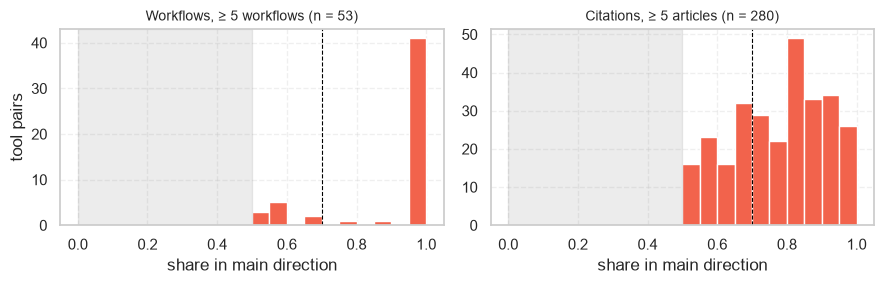

In [ ]:
MIN_CIT = 5   # articles
MIN_WF = 5    # workflows
BINS = np.linspace(0, 1, 21)  # 0.05 bins

s_wf = direction_df.loc[direction_df["wf_total"] >= MIN_WF, "wf_dir"]
s_cit = direction_df.loc[direction_df["cit_total"] >= MIN_CIT, "cit_dir"]
s_cit = np.maximum(s_cit, 1 - s_cit)  # update so its also on one side of 0.5: 0.2 -> 0.8

print(len(s_wf), len(s_cit))

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
axes[0].hist(s_wf, bins=BINS, color=COLOUR)
axes[0].set_title(f"Workflows, ≥ {MIN_WF} workflows (n = {len(s_wf)})", fontsize=10)
axes[1].hist(s_cit, bins=BINS, color=COLOUR)
axes[1].set_title(f"Citations, ≥ {MIN_CIT} articles (n = {len(s_cit)})", fontsize=10)

for ax in axes:
    ax.axvspan(0, 0.5, color="grey", alpha=0.15)  # not possible: main direction by definition
    ax.axvline(THRESHOLD, color="black", ls="--", lw=0.8)
    ax.set_xlabel("share in main direction")
axes[0].set_ylabel("tool pairs")
plt.tight_layout()
plt.show()

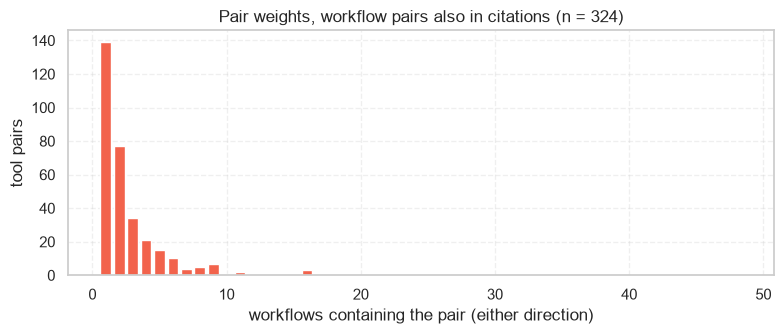

In [9]:
counts_wf = direction_df["wf_total"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts_wf.index, counts_wf.values, width=0.8, color=COLOUR)
ax.set_xlabel("workflows containing the pair (either direction)")
ax.set_ylabel("tool pairs")
ax.set_title(f"Pair weights, workflow pairs also in citations (n = {len(direction_df)})")
plt.tight_layout()
plt.show()